In [1]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)
df = df.asfreq("MS")   # đặt tần suất tháng: hết cảnh báo của SARIMAX và index dự báo đúng

## BÀI 5 NÂNG CAO: Xây dựng mô hình SARIMA

Bài 4 kết luận `SARIMA(0,1,1)(0,1,1)₁₂` (airline model). Bài 5 lấy log + chia train/test như Bài 3–4, fit mô hình trên tập train, rồi bàn giao cho bài 6 dự báo trên tập test.

In [3]:
p, d, q = 0, 1, 1
P, D, Q, s = 0, 1, 1, 12

In [4]:
# Log như Bài 3–4: biên độ mùa vụ tăng theo mức chuỗi (dạng nhân) nên log biến nó thành cộng
y = np.log(df["Passengers"])

# Chia 80/20 theo thời gian, không shuffle: 115 train / 29 test
k = int(len(y) * 0.8)
train_data = y.iloc[:k]
test_data  = y.iloc[k:]
print(f"Train: {len(train_data)} tháng ({train_data.index.min().date()} → {train_data.index.max().date()})")
print(f"Test : {len(test_data)} tháng ({test_data.index.min().date()} → {test_data.index.max().date()})")

model = SARIMAX(train_data, order=(p, d, q), seasonal_order=(P, D, Q, s))
results = model.fit()
print(f"AIC SARIMA(0,1,1)(0,1,1)12: {results.aic:.2f} | BIC: {results.bic:.2f}")

Train: 115 tháng (1949-01-01 → 1958-07-01)
Test : 29 tháng (1958-08-01 → 1960-12-01)


AIC SARIMA(0,1,1)(0,1,1)12: -372.17 | BIC: -364.30


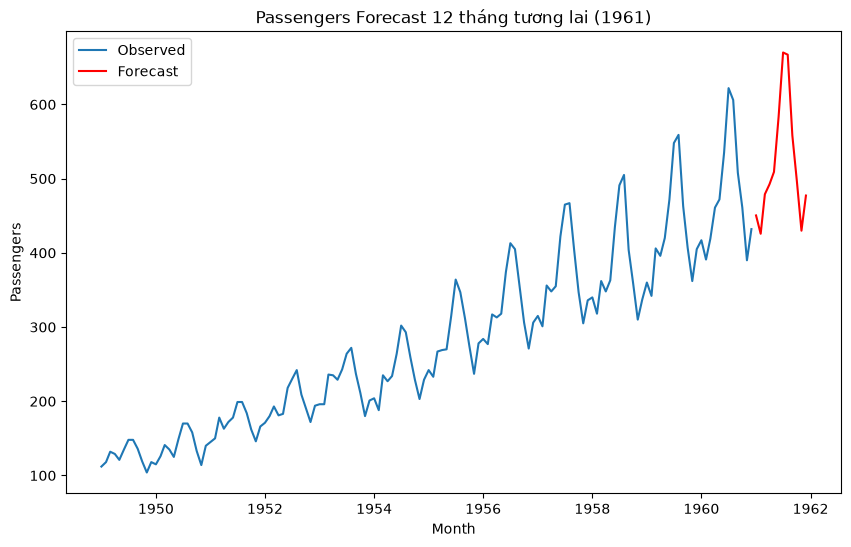

In [5]:
# Fit lại trên TOÀN BỘ 144 quan sát để dự báo 12 tháng tương lai (1961, chưa có actual).
# Khác bài 6: bài 6 chấm điểm trên 29 tháng test (có actual) — đừng lẫn.
forecast_periods = 12
final_model = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, s)).fit()
forecast = np.exp(final_model.forecast(steps=forecast_periods))   # exp vì model học trên log

plt.figure(figsize=(10, 6))
plt.plot(df["Passengers"], label="Observed")
plt.plot(forecast, label="Forecast", color="red")
plt.title("Passengers Forecast 12 tháng tương lai (1961)")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.show()

## So sánh với ARIMA

ARIMA(0,1,1) không có thành phần mùa vụ — fit trên cùng tập train để làm baseline.

In [6]:
model_arima = ARIMA(train_data, order=(p, d, q))
model_arima_fit = model_arima.fit()

print(f"AIC ARIMA(0,1,1) : {model_arima_fit.aic:.2f} | BIC: {model_arima_fit.bic:.2f}")
print(f"AIC SARIMA       : {results.aic:.2f} | BIC: {results.bic:.2f}")
# AIC hai mô hình KHÔNG so trực tiếp được: SARIMA có D=1 nên likelihood tính trên chuỗi khác (mất 13 quan sát).
# So sánh thật (MAE/RMSE/MAPE trên tập test) nằm ở bài 6.

AIC ARIMA(0,1,1) : -193.43 | BIC: -187.96
AIC SARIMA       : -372.17 | BIC: -364.30


**Kết luận bài 5:** đã fit `SARIMA(0,1,1)(0,1,1)₁₂` (airline model của Bài 4) và ARIMA(0,1,1) baseline trên cùng tập train (log, 115 tháng).

Bàn giao cho bài 6: `train_data`, `test_data`, order `(p, d, q)(P, D, Q, s)` — bài 6 dự báo 29 tháng test (1958-08 → 1960-12) để tính MAE/RMSE/MAPE và so SARIMA với ARIMA.